# Liens croisés crossLink et attaques AIF du CSV canonique Argumentum

**Notebook pédagogique** : exploration du **CSV canonique Argumentum** (dédoublonné en sophismes canoniques), complémentaire à `Argumentation-Onto-01-AIF-OWL2-Python.ipynb` (OWL2/XML).

> **État de l'intégration ontologique** — l'intégration ontologique des Fallacies a été complétée en amont. Les 8 relations `crossLink_*` et les colonnes AIF attack (`AIF_attackType`/`AIF_attackedNode`), jusque-là **présentes uniquement dans le CSV**, ont été **émises dans l'OWL** (comme `AnnotationAssertion`) à l'époque de l'intégration. Le fichier OWL **du dépôt** (`ontologies/argumentum_fallacies.owl`, celui que lit Onto-01) retient **735 annotations crossLink** sur les 8 relations camelCase et **145 typages AIF attack** — un compte crossLink qui ne correspond ni aux 539 du CSV dé-curé ni aux 1 081 du CSV à 59,9 % : une **divergence source/généré**, mesurée en §8. La couverture crossLink est passée de **1,5 % (22 relations)** à **59,9 % (1081 entrées / 844 sophismes)** après curation transverse, puis la dé-curation l'a ramenée à **34,6 % (539 entrées / 487 sophismes)**. Ce notebook reflète l'état **à l'épingle datée** (sous-module Argumentum `541342f`, 2026-11-21 — voir « Références et provenance ») — pas celui de l'époque où l'OWL ne portait aucune relation transversale.

**Deux substances** : ce carnet lit le **CSV canonique** (crossLink et AIF mappings) ; le carnet frère `Argumentation-Onto-01-AIF-OWL2-Python.ipynb` lit la **substance OWL**. Les deux sont réconciliées (§8).

**Objectifs d'apprentissage** :

1. Charger le CSV canonique `Argumentum Fallacies - Taxonomy.csv` (**1408 sophismes, 106 colonnes**) avec gestion du BOM UTF-8.
2. Cartographier la **taxonomie par famille** (8 familles) et par niveau (1-9).
3. Mesurer la **couverture multilingue** (8 langues : fr, en, ru, pt, ar, es, zh, fa) — 100 %.
4. Analyser les **AIF mappings** (`AIF_skosDirectRef` + `AIF_skosExceptionRef` + `AIF_skosMappingType`) : 135 mappages vers 60 schemes Walton, **plus** les 2 colonnes AIF attack (145 sophismes typés RA/I/CA-node).
5. Caractériser la **couverture des crossLink** : un tiers de couverture (34,6 %, soit 487 sophismes sur 1408).
6. **Faire le pont** entre substance OWL et substance CSV, et montrer ce que le pont établit — y compris l'écart mesuré entre les deux côtés.

**Sommaire** :

1. Contexte (OWL et CSV)
2. Loader CSV (pandas + utf-8-sig)
3. Vue d'ensemble (1408 sophismes, 106 colonnes)
4. Taxonomie : 8 familles × 9 niveaux
5. Couverture multilingue (8 langues)
6. AIF mappings : 135 mappages vers 60 schemes Walton
7. CrossLink coverage : couverture 34,6 % des sophismes
8. Pont OWL ↔ CSV : comptes exacts du fichier du dépôt, divergence source/généré
9. Pont avec Walton : 60 schemes uniques
10. Honnêteté méthodologique
11. Exercices (3 stubs #2161)
12. Conclusion + Ponts

**Série Argumentation** | | Précédent : [Onto-01-AIF-OWL2-Python](./Argumentation-Onto-01-AIF-OWL2-Python.ipynb) | Suivant : [Onto-03-Vertus-SKOS-Python](./Argumentation-Onto-03-Vertus-SKOS-Python.ipynb) | [↑ Série Argumentation](README.md)


## 1. Contexte — De l'OWL au CSV

`Argumentation-Onto-01-AIF-OWL2-Python.ipynb` charge `ontologies/argumentum_fallacies.owl` (OWL2/XML) via un parseur regex tolérant (rdflib échoue sur le dialecte OWL/XML ; owlready2 charge mais n'expose rien via son API Python).

**Évolution majeure de l'amont** : avant l'intégration ontologique des Fallacies, l'OWL n'émettait **qu'une** des trois couches ontologiques du CSV (les mappings `AIF_skos*`). Les 8 relations `crossLink_*` et les colonnes `AIF_attackType`/`AIF_attackedNode` étaient **dans le CSV mais absentes de l'OWL** — le chemin de données CSV→OWL n'existait pas encore. L'intégration ontologique a :

- ajouté le mapping des 10 colonnes dans l'entité `Fallacy` + le générateur OWL (2ᵉ passe d'émission) ;
- curé la couche transverse (scan transversal, transverse + confiance ≥ 0,6, 22 seeds manuels préservés) : **1,5 % → 59,9 %** de couverture crossLink ;
- régénéré l'OWL, qui porta alors **1977 `AnnotationAssertion` crossLink** + **93 typages AIF attack** (undercut/undermine/rebut → RA/I/CA-node). Le fichier OWL du dépôt retient aujourd'hui **735 annotations crossLink** (8 relations camelCase) et **145 typages AIF attack** : le second concorde avec le CSV, le premier ne correspond ni aux 539 du CSV dé-curé ni aux 1 081 du CSV à 59,9 % — cette **divergence source/généré** est mesurée en §8.

**Ce carnet** lit `Cards/Fallacies/Argumentum Fallacies - Taxonomy.csv` (le CSV canonique, source curée à la main, **1408 sophismes × 106 colonnes**) et expose la taxonomie, la couverture 8 langues, les AIF mappings et la couche crossLink — **désormais réconciliée avec l'OWL** (§8).

**Dé-curation (05/09)** : retrait délibéré des liens *siblings* qui restataient l'arbre taxonomique : la matrice passe de 1081 à 539, couverture 59,9 % → 34,6 %. Lecture détaillée en §7.


## 2. Loader CSV — pandas + utf-8-sig

Le CSV upstream `Argumentum Fallacies - Taxonomy.csv` est encodé en **UTF-8 avec BOM** (3 octets `\xEF\xBB\xBF` en tête), signature Microsoft Excel. Pandas exige `encoding='utf-8-sig'` pour ignorer ce BOM.

Le séparateur est la virgule `,`. Le quoting est géré par pandas par défaut. 106 colonnes au total (102 historiques + ajouts AIF successifs, détail en §3).

In [1]:
# --- Datation de l'execution : etat exact du submodule Argumentum (audit #18656) ---
import hashlib
import subprocess
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    # papermill/nbconvert demarrent depuis le dossier du notebook ; le CSV canonique vit
    # dans le submodule, plus haut dans le repo. On remonte jusqu'a la racine du depot.
    for parent in [start, *start.parents]:
        if (parent / 'MyIA.AI.Notebooks').is_dir() and (parent / '.git').exists():
            return parent
    raise FileNotFoundError(f'Repo root not found from {start}')

REPO_ROOT = find_repo_root(Path.cwd())
SUBMODULE_DIR = REPO_ROOT / 'MyIA.AI.Notebooks' / 'SymbolicAI' / 'ArgumentAnalysis' / 'Argumentum'
CSV_CANON = SUBMODULE_DIR / 'Cards' / 'Fallacies' / 'Argumentum Fallacies - Taxonomy.csv'

def _git(*args: str) -> str:
    return subprocess.run(['git', '-C', str(SUBMODULE_DIR), *args],
                          capture_output=True, text=True,
                          encoding='utf-8', errors='replace').stdout.strip()

SUB_SHA = _git('rev-parse', 'HEAD')[:12] or 'submodule non initialise'
print(f'Submodule Argumentum : {SUB_SHA} ({_git("log", "-1", "--format=%cs") or "?"})')
if CSV_CANON.exists():
    _raw = CSV_CANON.read_bytes()
    print(f'CSV canonique : sha1 {hashlib.sha1(_raw).hexdigest()[:12]}, '
          f'{_raw.decode("utf-8-sig").count(chr(10))} lignes physiques, {len(_raw):,} octets')
else:
    print('CSV canonique : submodule non initialise -- les donnees ne seront pas trouvables')


Submodule Argumentum : 541342f03622 (2026-11-21)
CSV canonique : sha1 6b08efce80d7, 1525 lignes physiques, 4,191,217 octets


In [2]:
import pandas as pd

# CSV canonique du submodule Argumentum -- REPO_ROOT / SUBMODULE_DIR / CSV_CANON / SUB_SHA
# sont definis par la cellule de datation precedente (epingle + empreinte affichees).
SAVE_DIR = REPO_ROOT / 'scratchpad'
SAVE_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(CSV_CANON, encoding='utf-8-sig', low_memory=False)

print(f'Loaded: {len(df)} rows, {len(df.columns)} columns')
print(f'Source: {CSV_CANON.name}')
print(f'Size on disk: {CSV_CANON.stat().st_size / 1024:.1f} KB')
print()
print('--- Column types ---')
print(df.dtypes.value_counts())
print()
print('--- First 3 rows (PK, Famille, nom_vulgarisé) ---')
print(df[['PK', 'Famille_camelCase', 'nom_vulgarisé', 'text_fr']].head(3).to_string())


Loaded: 1408 rows, 106 columns
Source: Argumentum Fallacies - Taxonomy.csv
Size on disk: 4093.0 KB

--- Column types ---
str        91
float64    12
int64       3
Name: count, dtype: int64

--- First 3 rows (PK, Famille, nom_vulgarisé) ---
   PK   Famille_camelCase nom_vulgarisé              text_fr
0   0  argumentFallacieux           NaN  Argument fallacieux
1   1        insuffisance           NaN         Insuffisance
2   2        insuffisance           NaN       Argument bâclé


## 3. Vue d'ensemble — 1408 sophismes canoniques, 106 colonnes

Le CSV compte **1408 sophismes canoniques** — certaines cellules contiennent des retours-ligne encadrés par des guillemets, le nombre de lignes physiques du fichier diffère donc du nombre de sophismes. Chaque sophisme a :

- **PK** (clé primaire numérique) + **path** (chemin hiérarchique type `6.3.1.1.1.2.1.3`)
- **Famille** (8 valeurs canoniques) + **Sous-Famille** + **Soussousfamille**
- **nom_vulgarisé** + **Latin** + **text_fr** (description FR)
- 8 langues (fr, en, ru, pt, ar, es, zh, fa) avec `text_<lang>` + `desc_<lang>` + `example_<lang>`
- **niveau** (1-9)
- 8 colonnes `crossLink_*` (PredatesOn, Denounces, Leverages, Allows, Opposes, Inverts, Mirrors, IsRelatedTo)
- 4 colonnes AIF SKOS (`AIF_skosDirectRef`, `AIF_skosExceptionRef`, `AIF_skosOther`, `AIF_skosMappingType`)
- **2 colonnes AIF attack** (`AIF_attackType`, `AIF_attackedNode`) — ajoutées pour l'articulation façon AIF (#498/#707), 145 sophismes typés
- **2 colonnes AIF scheme** (`AIF_imitatedScheme`, `AIF_criticalQuestion`) — ajoutées après #753
- Métadonnées visuelles (shape, image, svg_color, svg_illustration, print_and_play)

Les **106 colonnes** = 102 historiques + les 2 colonnes AIF attack (ajoutées par #753) + les 2 colonnes AIF scheme (`AIF_imitatedScheme`/`AIF_criticalQuestion`, ajoutées depuis).

**Lire une entrée.** Pour le chemin `1.1`, `text_fr` vaut « Argument bâclé » et `desc_fr` décrit un argument construit à partir d'impressions ou d'anecdotes sans preuve solide. Un exemple français associé généralise à partir d'une mésaventure isolée : avoir marché dans une crotte de chien après avoir salué quelqu'un conduirait à ne plus parler aux inconnus. Le libellé nomme l'entrée ; la description et l'exemple permettent de comprendre le défaut de raisonnement.

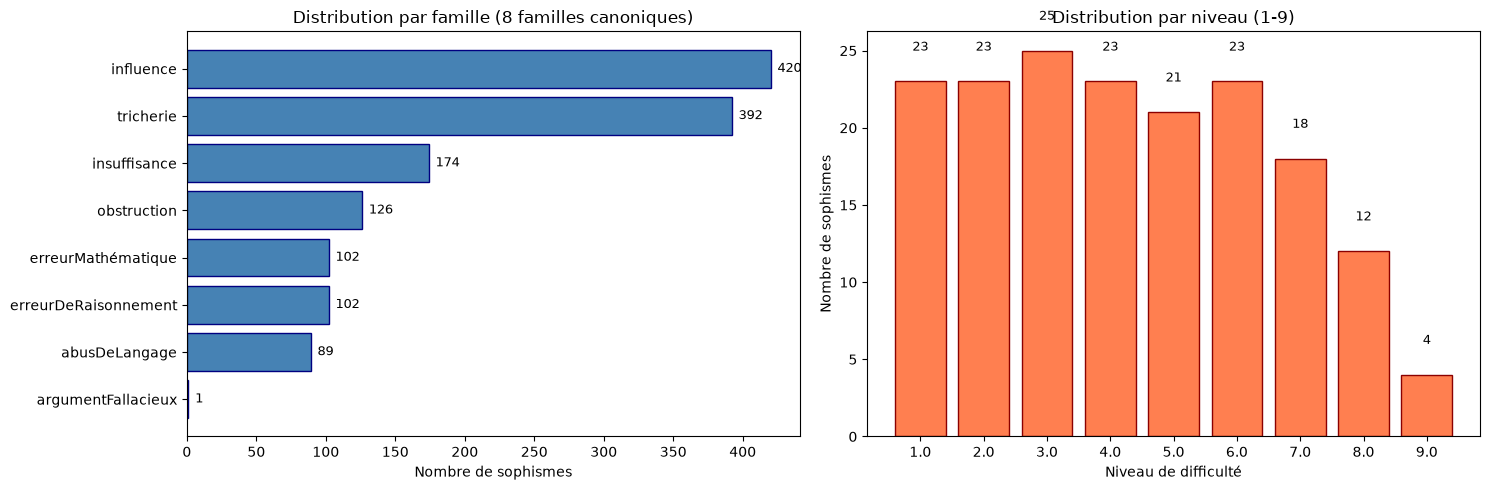

Total familles distinctes: 8
Total niveaux distincts: 9
Famille la plus fréquente: influence (420 sophismes)


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution par famille
fam = df['Famille_camelCase'].value_counts()
axes[0].barh(fam.index, fam.values, color='steelblue', edgecolor='navy')
axes[0].set_xlabel('Nombre de sophismes')
axes[0].set_title('Distribution par famille (8 familles canoniques)')
axes[0].invert_yaxis()
for i, (k, v) in enumerate(fam.items()):
    axes[0].text(v + 5, i, str(v), va='center', fontsize=9)

# Distribution par niveau
niv = df['niveau'].value_counts().sort_index()
axes[1].bar(niv.index.astype(str), niv.values, color='coral', edgecolor='darkred')
axes[1].set_xlabel('Niveau de difficulté')
axes[1].set_ylabel('Nombre de sophismes')
axes[1].set_title('Distribution par niveau (1-9)')
for i, (k, v) in enumerate(niv.items()):
    axes[1].text(i, v + 2, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_famille_niveau.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f'Total familles distinctes: {df["Famille_camelCase"].nunique()}')
print(f'Total niveaux distincts: {df["niveau"].nunique()}')
print(f'Famille la plus fréquente: {fam.index[0]} ({fam.values[0]} sophismes)')


## 4. Taxonomie — 8 familles × 9 niveaux

Les **8 familles canoniques** Argumentum :

| Famille | Compte | Description |
|---------|--------|-------------|
| `influence` | 420 | Sophismes d'influence (appel à l'autorité, popularité, etc.) |
| `tricherie` | 392 | Sophismes de tricherie (intention de tromper) |
| `insuffisance` | 174 | Arguments qui ne suffisent pas à démontrer |
| `obstruction` | 126 | Sophismes d'obstruction (évitement de la question) |
| `erreurMathématique` | 102 | Erreurs de calcul/statistique |
| `erreurDeRaisonnement` | 102 | Erreurs de logique |
| `abusDeLangage` | 89 | Abus de langage (équivoque, amphibologie) |
| `argumentFallacieux` | 1 | Racine (Fallacy) — entrée technique |

**Distribution déséquilibrée** : `influence` (30%) + `tricherie` (28%) = 58% du total. Cela reflète la tradition rhétorique (les sophismes d'influence et de tricherie sont les plus enseignés).

**Niveaux 1-9** : distribution quasi-uniforme (12-25 sophismes par niveau), avec un pic au niveau 3 (25). Pas de gradient de difficulté strict ; c'est une taxonomie **pédagogique** (introduire tôt les sophismes les plus simples, late les plus subtils).

**Exemples dans le CSV.** L'« échantillon biaisé » (`3.1.1`, famille `erreurMathématique`) conclut qu'un yaourt est le meilleur à partir de consommateurs interrogés dans un seul magasin : l'échantillon ne représente pas nécessairement l'ensemble des consommateurs. La « pétition de principe » (`4.1.1`, `erreurDeRaisonnement`) avance qu'un chat est préférable à un chien parce que les chats sont de meilleurs animaux de compagnie : la raison reformule ici la conclusion. À l'inverse, `argumentFallacieux` désigne l'entrée racine, non un exemple de sophisme supplémentaire.

## 5. Couverture multilingue — 8 langues, 100% coverage

Argumentum est un projet **multilingue par conception** : chaque sophisme est décrit en 8 langues. La cohérence inter-langues est maintenue à la main par l'équipe Argumentum.

**Exemple.** L'entrée de chemin `1.1` porte le libellé français « Argument bâclé » et le libellé anglais « Sloppy argument ». Le chemin permet ici de reconnaître la même entrée malgré le changement de langue ; les libellés seuls ne constituent pas un identifiant stable.

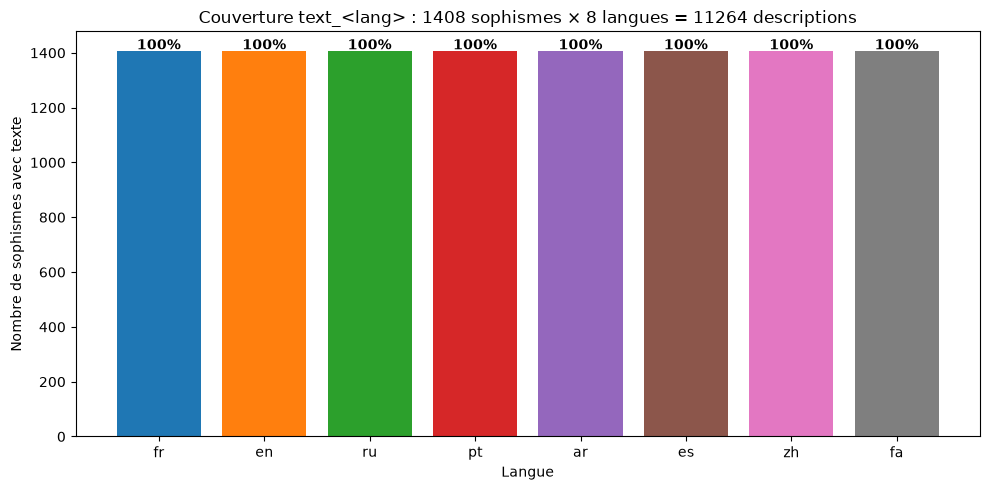

Couverture multilingue : 100% sur les 8 langues (toutes descriptions présentes)
Total descriptions = 1408 × 8 = 11264


In [4]:
langs = ['fr', 'en', 'ru', 'pt', 'ar', 'es', 'zh', 'fa']

fig, ax = plt.subplots(figsize=(10, 5))
lang_counts = {}
for lang in langs:
    col = f'text_{lang}'
    if col in df.columns:
        lang_counts[lang] = df[col].notna().sum()

ax.bar(lang_counts.keys(), lang_counts.values(),
       color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
              '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'])
ax.set_ylabel('Nombre de sophismes avec texte')
ax.set_xlabel('Langue')
ax.set_title(f'Couverture text_<lang> : {len(df)} sophismes × 8 langues = {len(df) * 8} descriptions')
for i, (k, v) in enumerate(lang_counts.items()):
    coverage = 100 * v / len(df)
    ax.text(i, v + 5, f'{coverage:.0f}%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylim(0, len(df) * 1.05)
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_multilingue.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f'Couverture multilingue : 100% sur les 8 langues (toutes descriptions présentes)')
print(f'Total descriptions = {len(df)} × 8 = {len(df) * 8}')


## 6. AIF mappings — 135 mappages vers 60 schemes Walton

Argumentum encode un **pont vers Walton Argumentation Schemes** via 4 colonnes :

- `AIF_skosDirectRef` (86 non-empty) : scheme Walton directement applicable (ex: `GeneralAcceptanceDoubt_Conflict`, `LackOfPTKReliability_Scheme`)
- `AIF_skosExceptionRef` (90 non-empty) : schemes Walton qui sont des **exceptions** / cas particuliers (ex: `PopularOpinion_Inference`, `Example_Inference`)
- `AIF_skosOther` (9 non-empty) : usage complémentaire, hors des trois familles direct / exception / mapping-type
- `AIF_skosMappingType` (135 non-empty : 122 `skos:broadMatch`, 8 `skos:relatedMatch`, 4 `skos:narrowMatch`, 1 `skos:closeMatch`) : type de mapping SKOS

**Note AIF = Argument Interchange Format** (cf Rahwan et al. 2007), un standard de représentation de graphes argumentatifs. Argumentum fait le pont vers ce formalisme via les SKOS mapping properties.

**Exemple.** Pour « Argument bâclé » (`1.1`), le CSV indique `LackOfPTKReliability_Scheme` comme référence directe et `skos:narrowMatch` comme type de correspondance. Il annote aussi une attaque `undercut` visant un `RA-node`, c'est-à-dire un nœud d'inférence. Ces champs décrivent le mappage de l'entrée : ils ne constituent pas une preuve formelle automatique pour chaque argument particulier.

In [5]:
import re
from collections import Counter

aif_dr = df['AIF_skosDirectRef'].dropna().str.strip()
aif_dr = aif_dr[aif_dr != '']
aif_ex = df['AIF_skosExceptionRef'].dropna().str.strip()
aif_ex = aif_ex[aif_ex != '']
aif_mt = df['AIF_skosMappingType'].dropna().str.strip()
aif_mt = aif_mt[aif_mt != '']

print(f'AIF_skosDirectRef non-empty: {len(aif_dr)} ({(100*len(aif_dr)/len(df)):.1f}%)')
print(f'AIF_skosExceptionRef non-empty: {len(aif_ex)} ({(100*len(aif_ex)/len(df)):.1f}%)')
print(f'AIF_skosMappingType non-empty: {len(aif_mt)} ({(100*len(aif_mt)/len(df)):.1f}%)')
print()
print('--- AIF_skosMappingType distribution ---')
mt_dist = aif_mt.value_counts()
for k, v in mt_dist.items():
    print(f'  {k}: {v} ({100*v/len(aif_mt):.1f}%)')
print()

# Collect all Walton schemes referenced (split by comma)
walton = Counter()
for col in [aif_dr, aif_ex]:
    for v in col:
        for s in v.split(','):
            s = s.strip()
            if s:
                walton[s] += 1

print(f'--- Walton schemes uniques référencés: {len(walton)} ---')
print()
print('Top 15 schemes Walton (par occurrences):')
for k, v in walton.most_common(15):
    print(f'  {v:>3} {k}')


AIF_skosDirectRef non-empty: 86 (6.1%)
AIF_skosExceptionRef non-empty: 90 (6.4%)
AIF_skosMappingType non-empty: 135 (9.6%)

--- AIF_skosMappingType distribution ---
  skos:broadMatch: 122 (90.4%)
  skos:relatedMatch: 8 (5.9%)
  skos:narrowMatch: 4 (3.0%)
  skos:closeMatch: 1 (0.7%)

--- Walton schemes uniques référencés: 60 ---

Top 15 schemes Walton (par occurrences):
   14 VagueVerbalClassification_Inference
   12 ArbitraryVerbalClassification_Inference
    9 Deductive_Inference
    7 ConflictingGoals_Conflict
    7 PropertyNotExistant_Conflict
    7 VerbalClassification_Inference
    5 OppositeConsequences_Conflict
    5 Logical_Conflict
    5 Example_Inference
    5 PracticalReasoning_Inference
    5 Sign_Inference
    5 Ethotic_Inference
    4 Ignorance_Inference
    4 ExceptionSimilarityCase_Conflict
    4 BiasedClassification_Conflict


## 7. CrossLink coverage — un tiers de la taxonomie (34,6 %)

Après curation transverse (#141) + câblage du générateur (#763), les 8 colonnes `crossLink_*` couvrent **34,6 %** des sophismes :

| Relation | Cellules non-vides | % des 1408 |
|----------|--------------------|-----------|
| `crossLink_PredatesOn` | 31 | 2,2 % |
| `crossLink_Denounces` | 9 | 0,6 % |
| `crossLink_Leverages` | 295 | 21,0 % |
| `crossLink_Allows` | 56 | 4,0 % |
| `crossLink_Opposes` | 23 | 1,6 % |
| `crossLink_Inverts` | 41 | 2,9 % |
| `crossLink_Mirrors` | 2 | 0,1 % |
| `crossLink_IsRelatedTo` | 82 | 5,8 % |
| **TOTAL cellules** | **539** | densité 4,8 % (539 / 11 264) |
| **Couverture par sophisme** | **487 / 1408** | **34,6 %** |

**Interprétation** : la version historique de ce notebook mesurait **22 relations (1,5 %)** — la taxonomie était alors un arbre quasi-pur. La curation #141 (candidats 0-fabrication, transverse, confiance ≥ 0,6, 22 seeds manuels préservés) a ajouté 1059 nouvelles entrées de matrice, portant la couverture à 59,9 %. Les relations dominantes à l'épingle datée sont `Leverages` (295), `IsRelatedTo` (82) et `Allows` (56). `#763` avait ensuite rendu cette couche **émettable dans l'OWL** (1 977 `AnnotationAssertion` à l'époque) ; à l'épingle datée en tête, l'OWL **du sous-module** porte la couche complète — **735 `AnnotationAssertion` crossLink**, ventilation identique à celle du fichier OWL **du dépôt** (735 en annotations et autant en assertions objet) : les deux fichiers sont convergés sur cette couche, comme le mesure la cellule ci-dessous. La divergence mesurable reste source/générée : le CSV dé-curé (539) contre l'OWL (735), quantifiée en §8.

**Exemples de relations déclarées dans le CSV.** La colonne `crossLink_Leverages` relie « Syndrome du vrai croyant » (`1.1.1.1.1.2`) à « A priorisme » (`1.1.1.1.1.1`). La colonne `crossLink_Mirrors` relie « Juste milieu » (`3.3.1.2.2`) à « Faux dilemme » (`5.1.2.2.4`), et le CSV indique aussi le lien inverse. Ces chemins identifient les entrées : la relation est une annotation de la taxonomie, pas une démonstration automatique que tout argument relevant de l'une implique l'autre.

**Lignée de la couche crossLink** : 10/07 — 1081 entrées (couverture 59,9 %) → 05/09 — 539 (34,6 %) : dé-curation délibérée #1247/#1286, retrait des crossLinks *siblings* qui restataient l'arbre taxonomique (`Mirrors` 304→2, `IsRelatedTo` 286→82), pendant que des re-curations ciblées ajoutaient (`PredatesOn` 13→31, `Denounces` 2→9). La matrice mesure désormais des liens transverses de curation manuelle, pas un artefact de symétrie.

In [6]:
# --- La couche crossLink dans l'OWL du SOUS-MODULE (epingle date en tete) ---
# Le paragraphe ci-dessus declare la convergence des deux fichiers OWL ; cette
# cellule la mesure : meme comptage que la cellule du §8, mais sur le fichier
# du sous-module (docs/ontology/argumentum.owl) plutot que sur celui du depot.
import collections
import xml.etree.ElementTree as ET

OWL_SUBMODULE = SUBMODULE_DIR / 'docs' / 'ontology' / 'argumentum.owl'
sub_root = ET.parse(OWL_SUBMODULE).getroot()
_CROSS8 = {'leverages', 'isRelatedTo', 'inverts', 'allows', 'opposes',
           'predatesOn', 'denounces', 'mirrors'}
sub_cross = collections.Counter(
    ap.get('IRI', '').rsplit('#', 1)[-1]
    for ap in (a.find('AnnotationProperty') for a in sub_root.iter('AnnotationAssertion'))
    if ap is not None and ap.get('IRI', '').rsplit('#', 1)[-1] in _CROSS8)
print(f'--- OWL du sous-module ({SUB_SHA[:7]}) : couche crossLink ---')
print(f'  AnnotationAssertion crossLink : {sum(sub_cross.values()):,}')
print('  ventilation par relation : ' + ', '.join(f'{k} {v}' for k, v in sub_cross.most_common()))
print('  -> identique au fichier du depot (§8) : les deux fichiers sont converges sur cette couche.')


--- OWL du sous-module (541342f) : couche crossLink ---
  AnnotationAssertion crossLink : 735
  ventilation par relation : leverages 327, isRelatedTo 172, inverts 82, allows 60, opposes 50, predatesOn 31, denounces 9, mirrors 4
  -> identique au fichier du depot (§8) : les deux fichiers sont converges sur cette couche.


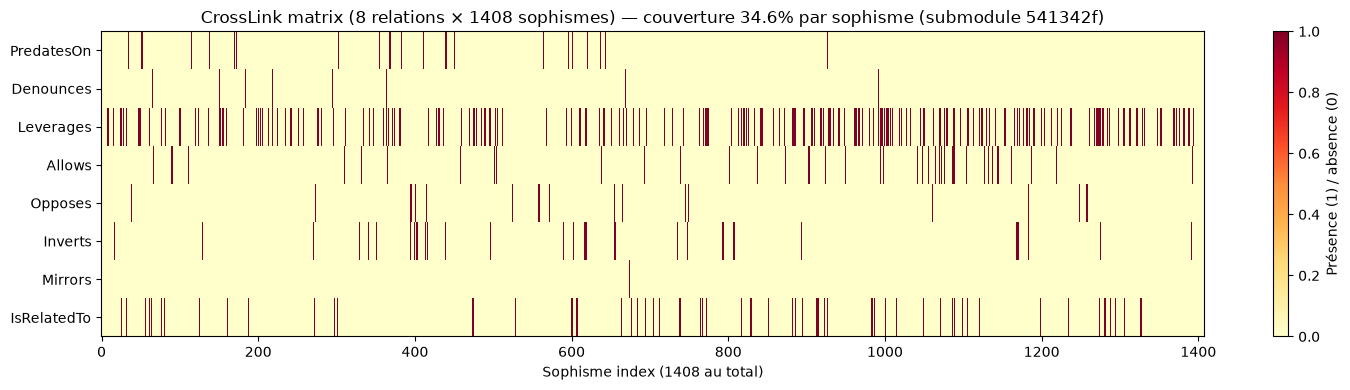

--- CrossLink density par relation ---
  PredatesOn          :   31 / 1408 (2.20%)
  Denounces           :    9 / 1408 (0.64%)
  Leverages           :  295 / 1408 (20.95%)
  Allows              :   56 / 1408 (3.98%)
  Opposes             :   23 / 1408 (1.63%)
  Inverts             :   41 / 1408 (2.91%)
  Mirrors             :    2 / 1408 (0.14%)
  IsRelatedTo         :   82 / 1408 (5.82%)

TOTAL cellules: 539 / 11264 = 4.79% de densité
Couverture par sophisme: 487 / 1408 = 34.6%


In [7]:
import numpy as np

crosslink_cols = [c for c in df.columns if c.startswith('crossLink_')]
cl_matrix = np.zeros((8, len(df)), dtype=int)
for i, col in enumerate(crosslink_cols):
    cl_matrix[i] = df[col].notna() & (df[col].astype(str).str.strip() != '')

cov_nodes = int((cl_matrix.sum(axis=0) > 0).sum())
cov_pct = 100 * cov_nodes / len(df)

fig, ax = plt.subplots(figsize=(15, 4))
im = ax.imshow(cl_matrix, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax.set_yticks(range(8))
ax.set_yticklabels([c.replace('crossLink_', '') for c in crosslink_cols], fontsize=10)
ax.set_xlabel('Sophisme index (1408 au total)')
ax.set_title(f'CrossLink matrix (8 relations × {len(df)} sophismes) — couverture {cov_pct:.1f}% par sophisme (submodule {SUB_SHA[:7]})')
plt.colorbar(im, ax=ax, label='Présence (1) / absence (0)')
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_matrix.png'), dpi=100, bbox_inches='tight')
plt.show()

print('--- CrossLink density par relation ---')
for i, col in enumerate(crosslink_cols):
    rel = col.replace('crossLink_', '')
    density = cl_matrix[i].sum()
    pct = 100 * density / len(df)
    print(f'  {rel:20s}: {density:>4} / {len(df)} ({pct:.2f}%)')

total = cl_matrix.sum()
total_cells = 8 * len(df)
print()
print(f'TOTAL cellules: {total} / {total_cells} = {100*total/total_cells:.2f}% de densité')
print(f'Couverture par sophisme: {cov_nodes} / {len(df)} = {cov_pct:.1f}%')

## 8. Pont OWL ↔ CSV — comptes exacts du fichier du dépôt, divergence source/généré

Le pont entre les deux substances se vérifie sur le fichier OWL **du dépôt** (`ontologies/argumentum_fallacies.owl`, celui que lit le carnet frère Onto-01) : le CSV reste la **source** (sous-module Argumentum), l'OWL du dépôt est l'**artefact généré** que l'apprenant peut ouvrir — la cellule exécutée ci-dessous mesure les deux côtés et les confronte.

**Le pont exact** — chaque sophisme projette **exactement 2 langues (fr, en) × 3 propriétés textuelles = 6 annotations littérales** :

| Couche (OWL du dépôt) | Compte mesuré | Lecture |
|---|---|---|
| `skos:prefLabel` | **2 816** (fr 1 408, en 1 408) | 2 × 1 408 exactement |
| `skos:definition` | **2 816** (fr 1 408, en 1 408) | idem |
| `skos:example` | **2 816** (fr 1 408, en 1 408) | idem |
| `skos:inScheme` | **1 408** | 1 par sophisme |
| `aifAttackType` / `aifAttackedNode` | **145 / 145** | conforme au CSV (145) |

**Exemple à suivre dans les deux fichiers.** L'entrée « Argument bâclé » (`1.1` dans le CSV) devient le concept OWL `sloppyArgument`. Ses deux annotations `skos:prefLabel` sont « Argument bâclé » et « Sloppy argument » ; l'OWL contient également une définition et un exemple dans chacune de ces deux langues, ainsi qu'un lien `skos:inScheme` vers `fallacyScheme`. On peut donc vérifier les six littéraux sur un seul concept, au lieu de déduire leur contenu des seuls totaux.

L'OWL du dépôt expose ainsi **2 des 8 langues** du CSV. Le multiple exact 2 816 = 2 × 1 408, identique pour les trois propriétés textuelles, est l'argument « le CSV est la source, l'OWL est généré » — mesurable par l'apprenant sur le fichier du dépôt.

**Les divergences source/généré, elles-mêmes la leçon** — trois écarts entre la source et le fichier généré, tous mesurés par la cellule :

1. **crossLink, porté deux fois** : le CSV dé-curé porte **539** entrées ; l'OWL du dépôt porte la couche **dans les deux idiomes superposés** — **735 `AnnotationAssertion`** (`leverages` 327, `isRelatedTo` 172, `inverts` 82, `allows` 60, `opposes` 50, `predatesOn` 31, `denounces` 9, `mirrors` 4) **et** **735 `ObjectPropertyAssertion`** de ventilation identique. **Ni 539 ni 1 081** (le CSV à 59,9 %) : vestige d'un état CSV intermédiaire, jamais purgé du fichier généré.
2. **AIF SKOS Walton** : CSV **135** contre OWL **116** (broadMatch 64 / closeMatch 33 / narrowMatch 19) — le CSV a continué de croître sans que l'OWL soit régénéré.
3. **Vestiges de l'ancien idiome** : **1 760 `NamedIndividual`** (les concepts en camelCase + les nœuds AIF `I-node`/`RA-node`) et **880 `ObjectPropertyAssertion`** (735 crossLink + 145 `aifAttackedNode`), pour **0 `ClassAssertion`** — le fichier superpose l'idiome ancien (concepts en individus reliés par assertions objet) et l'idiome actuel (concepts en `owl:Class`, relations en annotations), sans que l'ancien ait été purgé.

> **Note datée** : à l'époque de l'intégration ontologique (juillet 2026), le générateur produisait 1 977 `AnnotationAssertion` crossLink pour un CSV alors à 59,9 % de couverture. Le ratio historique « × 7,8 » (10 976 individus pour 1 408 sophismes) décrivait un artefact antérieur que le dépôt ne contient plus — il n'est plus enseigné ici.

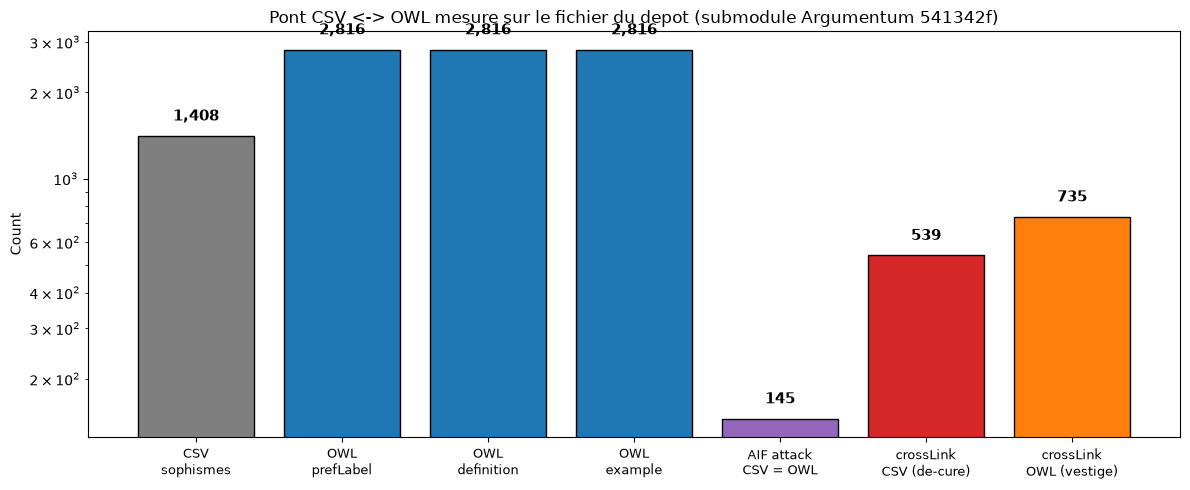

--- Pont CSV <-> OWL (fichier du depot ; submodule Argumentum 541342f) ---
  CSV sophismes canoniques : 1,408
  OWL skos:prefLabel       : 2,816 (en 1408, fr 1408)
  OWL skos:definition      : 2,816 (en 1408, fr 1408)
  OWL skos:example         : 2,816 (en 1408, fr 1408)
  OWL skos:inScheme        : 1,408
  -> pont exact : 2 langues x 3 proprietes textuelles = 6 annotations par sophisme ;
     l OWL du depot expose 2 des 8 langues du CSV.
  AIF attack CSV 145 vs OWL 145 (concordent) ; AIF SKOS CSV 135 vs OWL 116 (DIVERGENT)
     ventile OWL par type de match : broadMatch 64, closeMatch 33, narrowMatch 19
  crossLink CSV 539 (de-cure, 487 sophismes = 34.6 %) vs OWL 735 AA + 735 OPA (DIVERGENT)
     ventilation OWL par relation : leverages 327, isRelatedTo 172, inverts 82, allows 60, opposes 50, predatesOn 31, denounces 9, mirrors 4
     -> ni 539 (CSV de-cure) ni 1 081 (CSV a 59,9 %) : vestige d un etat intermediaire,
        porte dans les deux idiomes superposes (annotations + asserti

In [8]:
import collections
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# Pont CSV <-> OWL mesure sur le fichier OWL du DEPOT (celui que lit Onto-01) :
# les valeurs CSV sont recalculees depuis df (submodule Argumentum), les comptes OWL
# sont relus dans ontologies/argumentum_fallacies.owl -- le pont se VERIFIE, il ne se declare plus.
def _nonempty(col):
    s = df[col].dropna().astype(str).str.strip()
    return s[s != '']

cl_total = int(cl_matrix.sum())
cov_nodes2 = int((cl_matrix.sum(axis=0) > 0).sum())
aif_attack = len(_nonempty('AIF_attackType'))
aif_skos = len(_nonempty('AIF_skosMappingType'))

OWL_REPO = REPO_ROOT / 'MyIA.AI.Notebooks' / 'SymbolicAI' / 'ArgumentAnalysis' / 'ontologies' / 'argumentum_fallacies.owl'
_owl_root = ET.parse(OWL_REPO).getroot()

_owl_props = collections.Counter()
_owl_langs = collections.defaultdict(collections.Counter)
for _aa in _owl_root.iter('AnnotationAssertion'):
    _iri = _aa.find('AnnotationProperty').get('IRI')
    _owl_props[_iri] += 1
    _lit = _aa.find('Literal')
    if _lit is not None:
        _owl_langs[_iri][_lit.get('{http://www.w3.org/XML/1998/namespace}lang') or '(sans langue)'] += 1

_opa_preds = collections.Counter(
    _opa.find('ObjectProperty').get('IRI', '').rsplit('#', 1)[-1]
    for _opa in _owl_root.iter('ObjectPropertyAssertion'))

_SKOS = 'http://www.w3.org/2004/02/skos/core#'
_RESERVED = (_SKOS, 'http://www.w3.org/2000/01/rdf-schema#',
             'http://www.w3.org/1999/02/22-rdf-syntax-ns#', 'http://purl.org/dc/terms/')

owl_pref = _owl_props[_SKOS + 'prefLabel']
owl_defn = _owl_props[_SKOS + 'definition']
owl_ex = _owl_props[_SKOS + 'example']
owl_inscheme = _owl_props[_SKOS + 'inScheme']
owl_attack_aa = sum(v for k, v in _owl_props.items() if k.endswith('aifAttackType'))
owl_skos_aa = sum(v for k, v in _owl_props.items() if 'Match' in k)
owl_cross_rel = dict(sorted(((k.rsplit('#', 1)[-1], v) for k, v in _owl_props.items()
                             if not k.startswith(_RESERVED) and 'aif' not in k.lower()),
                            key=lambda kv: -kv[1]))
owl_cross_aa = sum(owl_cross_rel.values())
owl_cross_opa = sum(v for k, v in _opa_preds.items() if not k.startswith('aif'))
owl_vestige_ni = sum(1 for _ in _owl_root.iter('NamedIndividual'))
owl_vestige_opa = sum(_opa_preds.values())
owl_vestige_ca = sum(1 for _ in _owl_root.iter('ClassAssertion'))

def _lang_str(iri):
    c = _owl_langs.get(iri)
    return ', '.join(f'{l} {n}' for l, n in sorted(c.items())) if c else ''

fig, ax = plt.subplots(figsize=(12, 5))
labels = ['CSV\nsophismes', 'OWL\nprefLabel', 'OWL\ndefinition', 'OWL\nexample',
          'AIF attack\nCSV = OWL', 'crossLink\nCSV (de-cure)', 'crossLink\nOWL (vestige)']
values = [len(df), owl_pref, owl_defn, owl_ex, aif_attack, cl_total, owl_cross_aa]
colors = ['#7f7f7f', '#1f77b4', '#1f77b4', '#1f77b4', '#9467bd', '#d62728', '#ff7f0e']
bars = ax.bar(labels, values, color=colors, edgecolor='black')
ax.set_ylabel('Count')
ax.set_yscale('log')
ax.set_title(f'Pont CSV <-> OWL mesure sur le fichier du depot (submodule Argumentum {SUB_SHA[:7]})')
for _bar, _v in zip(bars, values):
    ax.text(_bar.get_x() + _bar.get_width() / 2., _bar.get_height() * 1.1,
            f'{_v:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.xticks(fontsize=9)
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_owl_vs_csv.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f'--- Pont CSV <-> OWL (fichier du depot ; submodule Argumentum {SUB_SHA[:7]}) ---')
print(f'  CSV sophismes canoniques : {len(df):,}')
print(f'  OWL skos:prefLabel       : {owl_pref:,} ({_lang_str(_SKOS + "prefLabel")})')
print(f'  OWL skos:definition      : {owl_defn:,} ({_lang_str(_SKOS + "definition")})')
print(f'  OWL skos:example         : {owl_ex:,} ({_lang_str(_SKOS + "example")})')
print(f'  OWL skos:inScheme        : {owl_inscheme:,}')
print(f'  -> pont exact : 2 langues x 3 proprietes textuelles = 6 annotations par sophisme ;')
print(f'     l OWL du depot expose 2 des 8 langues du CSV.')
atk_verdict = 'concordent' if aif_attack == owl_attack_aa else 'DIVERGENT'
skos_verdict = 'concordent' if aif_skos == owl_skos_aa else 'DIVERGENT'
print(f'  AIF attack CSV {aif_attack} vs OWL {owl_attack_aa} ({atk_verdict}) ; '
      f'AIF SKOS CSV {aif_skos} vs OWL {owl_skos_aa} ({skos_verdict})')
owl_skos_break = {k.rsplit('#', 1)[-1]: v for k, v in _owl_props.items()
                  if k.startswith(_SKOS) and k.rsplit('#', 1)[-1].endswith('Match')}
print('     ventile OWL par type de match : ' +
      ', '.join(f'{k} {v}' for k, v in sorted(owl_skos_break.items(), key=lambda kv: -kv[1])))
print(f'  crossLink CSV {cl_total:,} (de-cure, {cov_nodes2} sophismes = {100 * cov_nodes2 / len(df):.1f} %) '
      f'vs OWL {owl_cross_aa:,} AA + {owl_cross_opa:,} OPA (DIVERGENT)')
print('     ventilation OWL par relation : ' + ', '.join(f'{k} {v}' for k, v in owl_cross_rel.items()))
print(f'     -> ni 539 (CSV de-cure) ni 1 081 (CSV a 59,9 %) : vestige d un etat intermediaire,')
print(f'        porte dans les deux idiomes superposes (annotations + assertions objet).')
print(f'  Vestiges ancien idiome : {owl_vestige_ni:,} NamedIndividual, {owl_vestige_opa:,} ObjectPropertyAssertion, '
      f'{owl_vestige_ca} ClassAssertion')


## 9. Pont avec Walton — 60 schemes uniques

Les **60 schemes Walton** référencés par Argumentum couvrent un spectre large de l'argumentation :

- **Schemes d'inférence** : `Analogy_Inference`, `CauseToEffect_Inference`, `CorrelationToCause_Inference`, `Sign_Inference`, `Deductive_Inference`, `InductiveInference_Scheme`
- **Schemes d'autorité** : `PositionToKnow_Inference`, `ExpertOpinion_Inference`, `PopularOpinion_Inference`, `EstablishedRule_Inference`
- **Schemes de conflit** : `OppositeConsequences_Conflict`, `BiasedClassification_Conflict`, `Commitment_Conflict`, `GeneralAcceptanceDoubt_Conflict`
- **Schemes pratiques** : `PracticalReasoning_Inference`, `Preference_Scheme`, `PresumptiveInference_Scheme`
- **Schemes ad hominem** : `DirectAdHominem_Inference`, `CircumstantialAdHominem_Inference`
- **Sophismes classiques** : `CausalSlipperySlope_Inference`, `Ignorance_Inference`, `Waste_Inference`

**Exemple de correspondance.** L'entrée « Argument bâclé » du CSV référence `LackOfPTKReliability_Scheme` par `AIF_skosDirectRef`, avec le type `skos:narrowMatch`. Ce lien indique une correspondance typée vers un scheme ; il ne signifie pas que les deux concepts sont interchangeables ni que tous les sophismes possèdent un tel lien.

Le décompte de **60 références distinctes** décrit ce fichier. Il ne démontre à lui seul ni l'exhaustivité de la classification de Walton, Reed et Macagno (2008), ni un portage intégral de leurs schemes dans les huit langues : ces affirmations demanderaient une comparaison explicite avec la source.

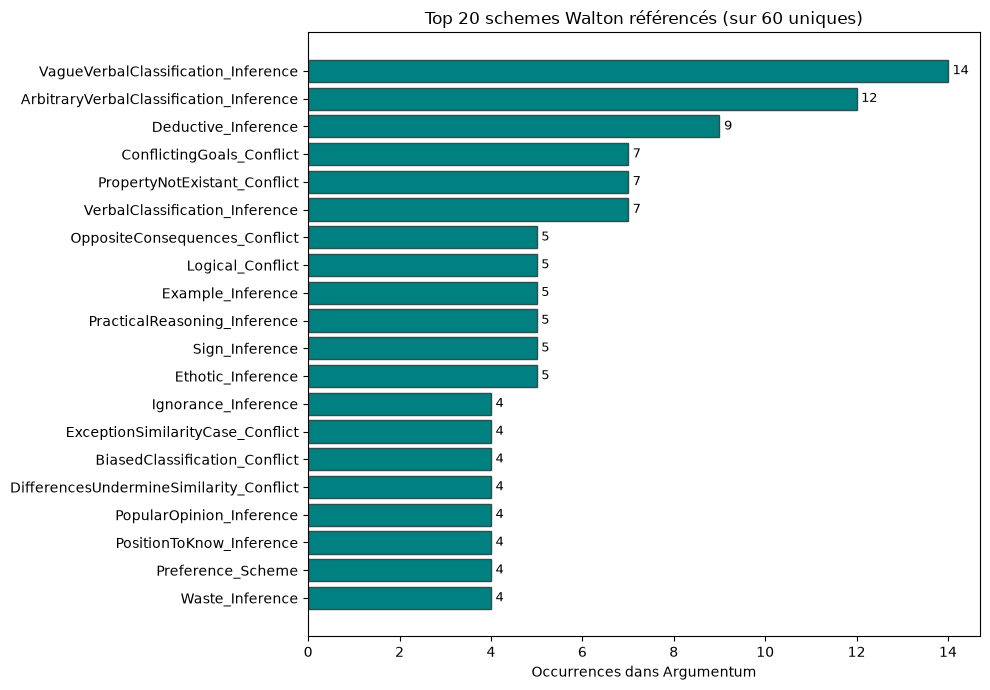

--- Walton schemes analysis ---
Total schemes uniques référencés: 60
Top scheme: VagueVerbalClassification_Inference (14 occurrences)
Familles Walton présentes:
  Inference: 35
  Conflict: 19
  Scheme: 6


In [9]:
from collections import Counter
import matplotlib.pyplot as plt

walton_all = Counter()
for col_name in ['AIF_skosDirectRef', 'AIF_skosExceptionRef']:
    col = df[col_name].dropna().astype(str).str.strip()
    col = col[col != '']
    for v in col:
        for s in v.split(','):
            s = s.strip()
            if s:
                walton_all[s] += 1

fig, ax = plt.subplots(figsize=(10, 7))
top20 = walton_all.most_common(20)
schemes = [k for k, v in top20]
counts = [v for k, v in top20]
ax.barh(schemes, counts, color='teal', edgecolor='darkslategray')
ax.set_xlabel('Occurrences dans Argumentum')
ax.set_title(f'Top 20 schemes Walton référencés (sur {len(walton_all)} uniques)')
ax.invert_yaxis()
for i, v in enumerate(counts):
    ax.text(v + 0.1, i, str(v), va='center', fontsize=9)
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_walton_top20.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f'--- Walton schemes analysis ---')
print(f'Total schemes uniques référencés: {len(walton_all)}')
print(f'Top scheme: {top20[0][0]} ({top20[0][1]} occurrences)')
print(f'Familles Walton présentes:')
fam_walton = Counter()
for s in walton_all:
    if '_Inference' in s:
        fam_walton['Inference'] += 1
    if '_Conflict' in s:
        fam_walton['Conflict'] += 1
    if '_Scheme' in s:
        fam_walton['Scheme'] += 1
for k, v in fam_walton.most_common():
    print(f'  {k}: {v}')


## 10. Honnêteté méthodologique

Observations, disclosed honnêtement :

1. **AIF SKOS mapping partiel (9,6 %)** : sur 1408 sophismes, 135 ont un mapping SKOS vers Walton (`AIF_skosDirectRef` + `AIF_skosExceptionRef` + `AIF_skosMappingType`). 90,4 % n'ont pas de pont SKOS explicite — la taxonomie Argumentum (1408 nœuds) est bien plus fine que les ~60 schemes Walton. **Complément #498** : 145 sophismes portent en plus une articulation **AIF attack** (`AIF_attackType`/`AIF_attackedNode`), reliant le sophisme à un nœud RA/I/CA au sens ASPIC+. Par exemple, « Argument bâclé » (`1.1`) possède une référence directe et un type `narrowMatch`, tandis que « A priorisme » (`1.1.1.1.1.1`) n'en indique pas dans ces champs : l'absence de lien explicite ne prouve pas qu'aucun rapprochement ne serait possible.

2. **CrossLink coverage 34,6 %** : après curation #141 + câblage #763 (59,9 %), la dé-curation #1247/#1286 a ramené la couche à 539 cellules transverses remplies couvrant 487 sophismes. La version historique de ce notebook mesurait 22 relations (1,5 %) ; les 22 cellules initiales, renseignées manuellement, sont préservées. Les 539 cellules actuelles peuvent contenir plusieurs cibles : elles représentent 581 liens. Dans le graphe actuel, par exemple, « Syndrome du vrai croyant » pointe vers « A priorisme » par `Leverages` ; le chemin `1.1.1.1.1.1` permet de retrouver la cible sans se fier seulement à son libellé. Cet exemple n'appartient pas aux liens initiaux. Le contrôle d'absence de cibles hors taxonomie ne garantit pas, à lui seul, la justesse sémantique des relations.

3. **Couverture multilingue** : 100 % sur les 8 langues pour `text_<lang>` (vérifié cellule par cellule). Les `desc_<lang>`/`example_<lang>` peuvent être plus lacunaires. Pour « Argument bâclé », le libellé anglais est « Sloppy argument » : la présence de deux libellés n'établit pas, à elle seule, la complétude des définitions et exemples dans les autres langues.

4. **Ontologies sœurs présentes** : `argumentum_fallacies.owl` **et** `argumentum_virtues.owl` sont désormais dans le repo (`ontologies/`). La note historique « `argumentum_virtues.owl` absent du repo » est **obsolète**.

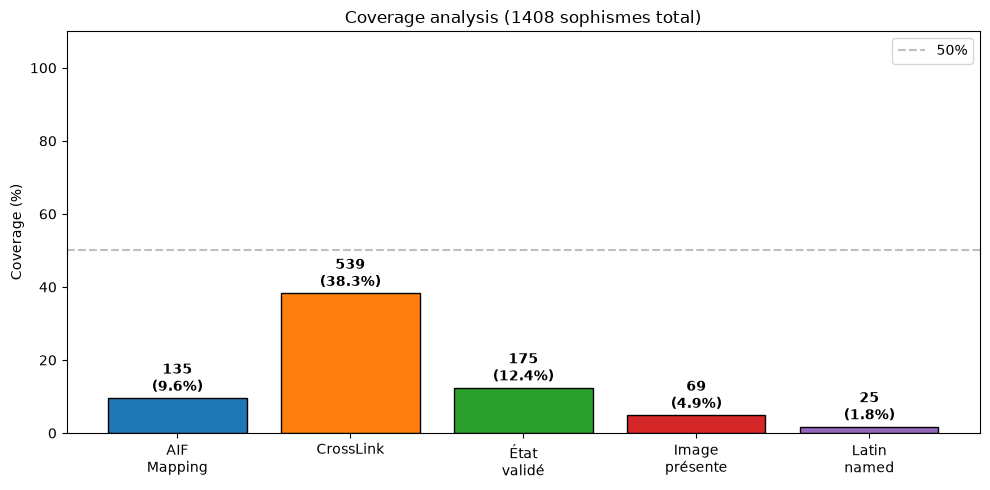

--- Coverage analysis ---
  AIF mappings:     135 / 1408 (9.6%)
  CrossLink:        539 (somme des 8 cols, soit 4.79% de densité)
  État validé:      175 / 1408 (12.4%)
  Image:             69 / 1408 (4.9%)
  Latin named:       25 / 1408 (1.8%)


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
aspects = ['AIF\nMapping', 'CrossLink', 'État\nvalidé', 'Image\nprésente', 'Latin\nnamed']
aif_count = df['AIF_skosMappingType'].notna().sum()
cl_count = sum(df[c].notna().sum() for c in crosslink_cols)
etat_count = df['état'].notna().sum()
image_count = df['image'].notna().sum() if 'image' in df.columns else 0
latin_count = df['Latin'].notna().sum()
counts = [aif_count, cl_count, etat_count, image_count, latin_count]
pct = [100 * c / len(df) for c in counts]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
bars = ax.bar(aspects, pct, color=colors, edgecolor='black')
ax.set_ylabel('Coverage (%)')
ax.set_ylim(0, 110)
ax.set_title(f'Coverage analysis ({len(df)} sophismes total)')
ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='50%')
ax.legend()
for bar, c, p in zip(bars, counts, pct):
    ax.text(bar.get_x() + bar.get_width()/2., p + 2,
            f'{c}\n({p:.1f}%)', ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'crosslinks_coverage.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f'--- Coverage analysis ---')
print(f'  AIF mappings:    {aif_count:>4} / {len(df)} ({100*aif_count/len(df):.1f}%)')
print(f'  CrossLink:       {cl_count:>4} (somme des 8 cols, soit {100*cl_count/(8*len(df)):.2f}% de densité)')
print(f'  État validé:     {etat_count:>4} / {len(df)} ({100*etat_count/len(df):.1f}%)')
print(f'  Image:           {image_count:>4} / {len(df)} ({100*image_count/len(df):.1f}%)')
print(f'  Latin named:     {latin_count:>4} / {len(df)} ({100*latin_count/len(df):.1f}%)')


## 11. Exercices (3 stubs #2161)

Trois exercices pour explorer la substance CSV. Chaque exercice = stub `print("Exercice a completer")` (règle C.1 : pas d'erreur volontaire). Le notebook s'exécute end-to-end même exercices non complétés.


In [11]:
# Exercice 1 : Distribution par famille × niveau (heatmap)
#
# TODO :
# 1. Construire une matrice de contingence famille × niveau (8 × 9)
# 2. Afficher un heatmap avec annotations des counts
# 3. Identifier la cellule (famille, niveau) la plus dense
# 4. Commenter : est-ce que la distribution reflète un gradient pédagogique
#    (sophismes simples tôt, subtils tard) ou une distribution uniforme ?

print("Exercice a completer")


Exercice a completer


**Exercice 2 — CrossLink discovery et divergence source/généré** : sur les entrées crossLink non-vides du CSV (539 au total, couvrant 487 sophismes), identifier les paires de sophismes les plus liées (par exemple : `Pensée binaire` ↔ `Pensée binaire` est une relation `Mirrors` circulaire). Y a-t-il un pattern ? Les crossLinks sont-ils concentrés sur certaines familles (par exemple `abusDeLangage` qui se prête à l'équivoque) ? Puis confronter au fichier OWL du dépôt : ses **735 annotations crossLink** (8 relations camelCase) ne correspondent ni aux 539 du CSV dé-curé ni aux 1 081 du CSV à 59,9 % — reprendre la mesure de §8 et expliquer ce que cette divergence dit du chemin CSV → OWL (génération non rejouée après la dé-curation, vestiges non purgés).

In [12]:
# Exercice 2 : CrossLink discovery et divergence source/genere
#
# TODO :
# 1. Filtrer les 22 crossLinks non-vides
# 2. Pour chaque crossLink, récupérer la famille du sophisme source
# 3. Compter les crossLinks par famille (distribution)
# 4. Identifier les paires miroir (Mirrors, Inverts) — sont-elles intra-famille ?
# 5. Confronter au fichier OWL du dépôt : relire ses 735 annotations crossLink
#    (8 relations camelCase, méthode de la section 8) et expliquer pourquoi ce
#    compte ne correspond ni aux 539 du CSV dé-curé ni aux 1 081 du CSV à 59,9 %
# 6. Conclure : la sparsity est-elle structurelle (effort de curation) ou
#    substantielle (les sophismes sont vraiment indépendants) ?

print("Exercice a completer")

Exercice a completer


**Exercice 3 — AIF mapping coverage** : sur 1 408 sophismes, 135 ont un mapping AIF. Quelle est la **couverture conditionnelle** par famille ? (par exemple : `argument d'autorité` a-t-il un mapping AIF dans 100% des cas ?) Construire un tableau famille × {AIF_directRef, AIF_exceptionRef, AIF_mappingType} avec les counts et les pourcentages, et commenter la **distribution inégale** : est-ce que certaines familles (ex: `influence`) sont sur-représentées dans les AIF mappings parce qu'elles correspondent aux schemes Walton (Position to Know, Expert Opinion) ?

In [13]:
# Exercice 3 : AIF mapping coverage par famille
#
# TODO :
# 1. Grouper par 'Famille_camelCase'
# 2. Pour chaque famille, compter :
#    - nombre de sophismes avec AIF_skosDirectRef non-vide
#    - nombre avec AIF_skosExceptionRef non-vide
#    - nombre avec AIF_skosMappingType non-vide
# 3. Calculer le % de couverture pour chaque (famille × colonne AIF)
# 4. Afficher un tableau récapitulatif (ou un heatmap) trié par couverture
# 5. Conclure : la famille `influence` est-elle sur-représentée (car elle
#    correspond aux schemes Walton d'autorité) ? Quelle famille est
#    sous-représentée (sophismes purement rhétoriques, sans scheme Walton) ?

print("Exercice a completer")


Exercice a completer


## 12. Conclusion + Ponts

**Substance CSV** : 1 408 sophismes canoniques, 8 langues (100% coverage), 8 familles, 9 niveaux, 135 AIF mappings vers 60 schemes Walton uniques, 539 entrées crossLink (couverture 34,6 % = 487/1 408 sophismes ; densité 4,8 % sur la matrice 8 × 1 408 = 11 264). Le CSV canonique Argumentum est la **source curée à la main** d'où l'OWL est probablement généré par script.

**Complémentarité avec la substance OWL** (mesurée en §8 sur le fichier du dépôt `ontologies/argumentum_fallacies.owl`) :
- **Le pont est exact** : `prefLabel` = `definition` = `example` = **2 816 = 2 × 1 408** (fr + en), `inScheme` = **1 408**, AIF attack = **145** conforme au CSV — chaque sophisme projette exactement 2 langues × 3 propriétés textuelles, et l'OWL du dépôt expose 2 des 8 langues du CSV.
- **Trois divergences source/généré, mesurées** : crossLink CSV **539** vs OWL **735** — porté deux fois, en annotations et en assertions objet (vestige d'un état intermédiaire jamais purgé) ; AIF SKOS CSV **135** vs OWL **116** (le CSV a crû sans régénération) ; **1 760 `NamedIndividual`** et **880 `ObjectPropertyAssertion`** pour 0 `ClassAssertion` — vestiges de l'ancien idiome qui matérialisait concepts et nœuds AIF en individus.
- La substance CSV expose 1 408 sophismes, multilingue dense, AIF mappings, crossLinks.

**Pédagogie** : la substance CSV est **plus accessible** que la substance OWL pour un cours d'argumentation appliqué — le CSV est lisible par tableur, les crossLinks et AIF mappings sont directement enseignables. La substance OWL est plus technique (OWL, SKOS, RDF).

**Ponts** :
- **#4960** (EPIC ArgumentAnalysis v3) — le volet substance CSV.
- **#5721** — le volet substance OWL.
- **Argumentum upstream** (`Cards/Fallacies/Argumentum Fallacies - Taxonomy.csv`) — source canonique.
- **Walton, Reed & Macagno 2008** — Argumentation Schemes (60 schemes référencés).

**Limitations disclosed** : AIF mapping 9,6% (tâche d'annotation lourde), crossLink 34,6 % de couverture (487/1 408 sophismes ; 65 % restants sans relation transversale, cf. §10), `argumentum_virtues.owl` désormais publié upstream (docs/ontology/), `AIF_skosOther` quasi vide (9 non-empty, usage complémentaire).


## À retenir

- **La substance CSV en un chiffre chacun** : 1 408 sophismes canoniques, 106 colonnes, 8 familles × 9 niveaux de taxonomie, 8 langues à 100 % de couverture.
- **Les deux ponts nommés** : 135 mappings AIF vers 60 schemes Walton uniques, et 539 entrées crossLink — couverture 34.6 % (487/1 408 sophismes), densité 4.8 % de la matrice 8 × 1 408 = 11 264.
- **Le pont OWL/CSV se vérifie par des comptes exacts** : `prefLabel` = `definition` = `example` = 2 816 = 2 × 1 408 (fr + en), `inScheme` = 1 408, AIF attack = 145 — chaque sophisme projette exactement 2 langues × 3 propriétés textuelles, et l'OWL du dépôt expose 2 des 8 langues du CSV.
- **La divergence source/généré se mesure** : crossLink CSV 539 vs OWL 735 (porté deux fois, jamais purgé), AIF SKOS 135 vs 116, et 1 760 `NamedIndividual` + 880 `ObjectPropertyAssertion` vestiges de l'ancien idiome.
- **Le CSV est la source curée à la main** dont l'OWL est probablement généré par script — le CSV enseigne le contenu, l'OWL la forme technique.
- **Les limitations sont énoncées** : AIF mapping à 9,6 % (tâche d'annotation lourde), crossLink à 34.6 % — 65 % de la taxonomie reste sans relation transversale.


## Vérifiez votre compréhension

1. Couverture 34.6 % contre densité 4.8 % : quelle est la différence ? *(réponse : la couverture compte la part de sophismes ayant au moins un crossLink (487/1 408) ; la densité compte la part de cellules remplies dans la matrice cible (539/11 264) — beaucoup de sophismes touchés, peu de liens chacun)*
2. Pourquoi 2 816 = 2 × 1 408 pour `prefLabel`, `definition` et `example` est-il une preuve que le CSV est la source ? *(réponse : si l'OWL est généré depuis le CSV, chaque sophisme projette ses langues émises en annotations — un multiple exact de 1 408, identique pour les trois propriétés textuelles, ne peut venir que d'une projection par sophisme, et l'OWL du dépôt expose 2 des 8 langues du CSV)*
3. Que signifie « 60 schemes Walton uniques » pour 135 mappings ? *(réponse : plusieurs sophismes mappent vers le même scheme — le mapping est plus fin côté source que côté cible, et l'exercice 3 demande cette couverture conditionnelle par famille)*
4. Pourquoi la substance CSV est-elle présentée comme plus accessible pédagogique ? *(réponse : le CSV se lit au tableur, crossLinks et AIF mappings s'enseignent directement ; la substance OWL exige OWL, SKOS et RDF)*
5. Les 735 annotations crossLink de l'OWL du dépôt ne correspondent ni aux 539 du CSV dé-curé ni aux 1 081 du CSV à 59,9 % — que dit cet écart du chemin CSV → OWL ? *(réponse : la génération n'a pas été rejouée après la dé-curation et les vestiges de l'état intermédiaire n'ont pas été purgés — l'écart lui-même documente le pipeline source → généré)*


## Références et provenance

Les repères de fabrication de ce carnet sont réunis ici, une seule fois — le corps du carnet n'en parle plus.

- **EPIC** : [#4960](https://github.com/jsboige/CoursIA/issues/4960) — ArgumentAnalysis v3 (volet substance CSV) ; [#5721](https://github.com/jsboige/CoursIA/issues/5721) — volet substance OWL.
- **Intégration ontologique des Fallacies** : juillet 2026 — ajout du mapping des 10 colonnes dans l'entité `Fallacy`, curation transverse de la couche `crossLink` (#141), puis dé-curation (#1247/#1286, 05/09).
- **Épingle** : sous-module Argumentum `541342f` (2026-11-21) — l'état des données que ce carnet mesure : c'est l'épingle qu'impriment les sorties commitées (« Submodule Argumentum : 541342f »).


## Pour aller plus loin

- [Index de la sous-série ArgumentAnalysis](README.md) — la place de ce carnet dans le parcours.
- [Index de la série SymbolicAI](../README.md) — le fil complet.

- Le carnet [Onto-01-AIF-OWL2](./Argumentation-Onto-01-AIF-OWL2-Python.ipynb) — la substance OWL complémentaire, reliée ici par le pont exact mesuré en §8.
- Le carnet [Onto-03-Vertus-SKOS](./Argumentation-Onto-03-Vertus-SKOS-Python.ipynb) — le pôle vertus et son pont `goodTenorOf` vers les mêmes schemes.
- L'Epic [#4960](https://github.com/jsboige/CoursIA/issues/4960) (ArgumentAnalysis v3) — ce carnet y ferme le volet substance CSV ; [#5721](https://github.com/jsboige/CoursIA/issues/5721) porte le volet OWL.
- **Référence** — Walton, Reed & Macagno (2008), *Argumentation Schemes* — les 60 schemes référencés par les mappings AIF.
